# EM43 Evaluator — y = x * (1 + x mod 2)

This notebook loads the two `parity_scaled` genomes, evaluates extrapolation on x=31..1000, creates space-time plots for x=33 and x=34, and exports CSV summaries.

Run cells from top to bottom after the Trainer has saved both `.npz` genome files.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import ast
import numpy as np
import matplotlib.pyplot as plt

DRIVE_ROOT = Path("/content/drive/MyDrive/EM43")
print("DRIVE_ROOT =", DRIVE_ROOT.resolve())
import pandas as pd


Mounted at /content/drive
DRIVE_ROOT = /content/drive/MyDrive/EM43


In [2]:
def lut_idx4(l: int, c: int, r: int) -> int:
    return (l * 4 + c) * 4 + r


IDX_000 = lut_idx4(0, 0, 0)
IDX_020 = lut_idx4(0, 2, 0)
IDX_200 = lut_idx4(2, 0, 0)
IDX_002 = lut_idx4(0, 0, 2)


def enforce_immutables_full(rule_full: np.ndarray) -> None:
    if rule_full.shape[-1] != 64:
        raise ValueError(f"rule_full last dimension must be 64, got {rule_full.shape}")
    rule_full[..., IDX_000] = 0
    rule_full[..., IDX_020] = 2
    rule_full[..., IDX_200] = 0
    rule_full[..., IDX_002] = 0


def parse_uint8_vector_string(s: str, expected_len: int | None = None, name: str = "vector") -> np.ndarray:
    s = s.strip()
    if not s:
        raise ValueError(f"{name} string is empty")

    if s[0] != "[":
        s = "[" + s + "]"

    try:
        obj = ast.literal_eval(s)
    except Exception as e:
        raise ValueError(f"Could not parse {name} string: {e}") from e

    arr = np.asarray(obj, dtype=np.int64).reshape(-1)

    if expected_len is not None and arr.shape[0] != expected_len:
        raise ValueError(f"{name} must have length {expected_len}, got {arr.shape[0]}")
    if np.any(arr < 0) or np.any(arr > 3):
        raise ValueError(f"{name} values must be in {{0,1,2,3}}")

    return arr.astype(np.uint8)


def parse_rule_program_strings(rule_str: str, prog_str: str):
    rule = parse_uint8_vector_string(rule_str, expected_len=64, name="rule")
    prog = parse_uint8_vector_string(prog_str, expected_len=None, name="program")
    enforce_immutables_full(rule)
    return rule, prog


def load_genome_from_drive(task_alias: str, run_id: int, drive_root: Path = DRIVE_ROOT):
    task_dir = drive_root / task_alias
    genome_path = task_dir / f"best_em43_{task_alias}_run_{run_id:03d}.npz"

    if not genome_path.exists():
        raise FileNotFoundError(f"Genome file not found: {genome_path}")

    data = np.load(genome_path, allow_pickle=True)

    rule_full = np.asarray(data["rule_full"], dtype=np.uint8).reshape(-1)
    program = np.asarray(data["program"], dtype=np.uint8).reshape(-1)

    if rule_full.shape != (64,):
        raise ValueError(f"Loaded rule has wrong shape: {rule_full.shape}")

    enforce_immutables_full(rule_full)

    meta = {
        "path": genome_path,
        "task_alias": str(data["task_alias"]) if "task_alias" in data else task_alias,
        "run": int(data["run"]) if "run" in data else run_id,
        "Lp": int(data["Lp"]) if "Lp" in data else int(program.shape[0]),
        "best_gen": int(data["best_gen"]) if "best_gen" in data else None,
        "fitness": float(data["fitness"]) if "fitness" in data else None,
        "mae": float(data["mae"]) if "mae" in data else None,
    }
    return rule_full, program, meta


def build_single_input_task(*, inputs, target_fn):
    xs = list(inputs)
    encoded_inputs = []
    targets = np.empty((len(xs),), dtype=np.int64)

    for i, x in enumerate(xs):
        if x < 0:
            raise ValueError(f"Input x={x} must be nonnegative")

        enc = np.zeros((x + 1,), dtype=np.uint8)
        enc[x] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(x))

    return encoded_inputs, targets


def build_two_input_task(*, pairs, target_fn):
    pairs = list(pairs)
    encoded_inputs = []
    targets = np.empty((len(pairs),), dtype=np.int64)

    for i, (a, b) in enumerate(pairs):
        if a < 0 or b < 0:
            raise ValueError(f"Inputs must be nonnegative, got {(a, b)}")

        L = max(a, b) + 1
        enc = np.zeros((L,), dtype=np.uint8)
        enc[a] = 2
        enc[b] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(a, b))

    return encoded_inputs, targets


class EM43NumpyEvaluator:
    """
    Pure-numpy EM43 evaluator.

    Matches training semantics:
      - same tape layout: [program][separator][encoding]
      - same LUT indexing
      - same synchronous radius-1 update
      - same halting rule: live > 0 and 2*ctrl >= live
      - same time-0 halting check
      - same immutables
      - if live == 0, continue until T_max

    Inference difference:
      - no right-boundary invalidation
      - initial usable tape length is:
            Lp + Ls + (max active input position + 1) + right_padding
      - right-only self-extension before step
      - decode over the whole usable right region from the fixed encoding origin
      - no left extension
    """

    def __init__(
        self,
        *,
        Lp: int,
        Ls: int = 4,
        T_max: int = 10000,
        right_padding: int = 20,
        extend_margin: int = 3,
        extend_by: int = 20,
    ):
        self.Lp = int(Lp)
        self.Ls = int(Ls)
        self.T_max = int(T_max)
        self.right_padding = int(right_padding)
        self.extend_margin = int(extend_margin)
        self.extend_by = int(extend_by)

        if self.Lp <= 0:
            raise ValueError("Lp must be positive")
        if self.Ls < 0:
            raise ValueError("Ls must be nonnegative")
        if self.T_max <= 0:
            raise ValueError("T_max must be positive")
        if self.right_padding < 0:
            raise ValueError("right_padding must be nonnegative")
        if self.extend_margin < 0:
            raise ValueError("extend_margin must be nonnegative")
        if self.extend_by <= 0:
            raise ValueError("extend_by must be positive")

        self.enc_origin = self.Lp + self.Ls

    def _validate_inputs(self, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray):
        if rule_full.shape != (64,):
            raise ValueError(f"rule_full shape must be (64,), got {rule_full.shape}")
        if program.ndim != 1 or program.shape[0] != self.Lp:
            raise ValueError(f"program shape must be ({self.Lp},), got {program.shape}")
        if enc.ndim != 1:
            raise ValueError(f"encoding must be 1D, got shape {enc.shape}")
        if enc.shape[0] <= 0:
            raise ValueError("encoding must be non-empty")

        if np.any(rule_full < 0) or np.any(rule_full > 3):
            raise ValueError("rule values must be in {0,1,2,3}")
        if np.any(program < 0) or np.any(program > 3):
            raise ValueError("program values must be in {0,1,2,3}")
        if np.any(enc < 0) or np.any(enc > 3):
            raise ValueError("encoding values must be in {0,1,2,3}")

    def _build_initial_tape(self, program: np.ndarray, enc: np.ndarray) -> np.ndarray:
        active = np.flatnonzero(enc != 0)
        if active.size == 0:
            enc_len_used = enc.shape[0]
        else:
            enc_len_used = int(active[-1]) + 1

        usable_len = self.Lp + self.Ls + enc_len_used + self.right_padding

        tape = np.zeros((usable_len,), dtype=np.uint8)
        tape[:self.Lp] = program
        tape[self.enc_origin:self.enc_origin + enc.shape[0]] = enc
        return tape

    @staticmethod
    def _count_live_ctrl(tape: np.ndarray):
        live = int(np.count_nonzero(tape))
        ctrl = int(np.count_nonzero(tape == 3))
        return live, ctrl

    @staticmethod
    def _rightmost_active_index(tape: np.ndarray):
        pos = np.flatnonzero(tape != 0)
        return None if pos.size == 0 else int(pos[-1])

    def _extend_if_needed(self, tape: np.ndarray) -> np.ndarray:
        r_active = self._rightmost_active_index(tape)
        if r_active is None:
            return tape

        right_edge = tape.shape[0] - 1
        if right_edge - r_active <= self.extend_margin:
            tape = np.concatenate([tape, np.zeros((self.extend_by,), dtype=np.uint8)])
        return tape

    @staticmethod
    def _step_once(rule_full: np.ndarray, tape: np.ndarray) -> np.ndarray:
        L = np.empty_like(tape)
        C = tape
        R = np.empty_like(tape)

        L[0] = 0
        L[1:] = tape[:-1]

        R[-1] = 0
        R[:-1] = tape[1:]

        idx = (L.astype(np.int32) * 4 + C.astype(np.int32)) * 4 + R.astype(np.int32)
        return rule_full[idx].astype(np.uint8, copy=False)

    def _decode(self, tape: np.ndarray):
        decode_region = tape[self.enc_origin:]
        pos = np.flatnonzero(decode_region == 2)
        return None if pos.size == 0 else int(pos[-1])

    def run_single(self, *, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray, return_trajectory: bool = False):
        rule = np.asarray(rule_full, dtype=np.uint8).copy()
        prog = np.asarray(program, dtype=np.uint8).copy()
        enc = np.asarray(enc, dtype=np.uint8).copy()

        enforce_immutables_full(rule)
        self._validate_inputs(rule, prog, enc)

        tape = self._build_initial_tape(prog, enc)
        n_extensions = 0
        trajectory = [tape.copy()] if return_trajectory else None

        live, ctrl = self._count_live_ctrl(tape)
        if live > 0 and ctrl * 2 >= live:
            pred = self._decode(tape)
            return {
                "pred": pred,
                "valid": pred is not None,
                "halted": True,
                "halt_time": 0,
                "n_extensions": n_extensions,
                "final_usable_len": int(tape.shape[0]),
                "trajectory": trajectory,
            }

        for t in range(1, self.T_max + 1):
            old_len = tape.shape[0]
            tape = self._extend_if_needed(tape)
            if tape.shape[0] != old_len:
                n_extensions += 1

            tape = self._step_once(rule, tape)

            if return_trajectory:
                trajectory.append(tape.copy())

            live, ctrl = self._count_live_ctrl(tape)
            if live > 0 and ctrl * 2 >= live:
                pred = self._decode(tape)
                return {
                    "pred": pred,
                    "valid": pred is not None,
                    "halted": True,
                    "halt_time": t,
                    "n_extensions": n_extensions,
                    "final_usable_len": int(tape.shape[0]),
                    "trajectory": trajectory,
                }

        return {
            "pred": None,
            "valid": False,
            "halted": False,
            "halt_time": None,
            "n_extensions": n_extensions,
            "final_usable_len": int(tape.shape[0]),
            "trajectory": trajectory,
        }

    def plot_trajectory(self, trajectory, *, title="EM43 trajectory", figsize=(14, 6), tick_step=10):
        if trajectory is None or len(trajectory) == 0:
            raise ValueError("trajectory is empty")

        max_len = max(row.shape[0] for row in trajectory)
        img = np.zeros((len(trajectory), max_len), dtype=np.uint8)
        for i, row in enumerate(trajectory):
            img[i, :row.shape[0]] = row

        from matplotlib.colors import ListedColormap, BoundaryNorm

        cmap = ListedColormap(["white", "black", "red", "blue"])
        norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

        fig, ax = plt.subplots(figsize=figsize)
        ax.imshow(
            img,
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
            aspect="equal",   # square cells
            origin="upper",
        )

        # Left boundary before cell 0
        ax.axvline(x=-0.5, color="gray", linewidth=2)

        # Encoding origin boundary x0 = enc_origin
        ax.axvline(x=self.enc_origin - 0.5, color="green", linewidth=2)

        ax.set_xlabel("Encoding position (relative to x0)")
        ax.set_ylabel("Time step")
        ax.set_title(title)

        ax.set_xlim(-0.5, max_len - 0.5)
        ax.set_ylim(len(trajectory) - 0.5, -0.5)

        # X ticks labeled relative to encoding origin
        tick_start = self.enc_origin
        ticks = np.arange(tick_start, max_len, tick_step)
        ax.set_xticks(ticks)
        ax.set_xticklabels((ticks - self.enc_origin).astype(int))

        plt.show()

# 1. Load trained genomes and configure task

In [3]:
# =========================
# LOAD TRAINED PARITY-SCALED GENOME
# =========================

task_alias = "parity_scaled"
expected_runs = 2
task_dir = DRIVE_ROOT / task_alias
genome_paths = sorted(task_dir.glob(f"best_em43_{task_alias}_run_*.npz"))
print("Task directory:", task_dir)
print("Found genomes:", len(genome_paths))
for p in genome_paths:
    print(" -", p.name)

if len(genome_paths) != expected_runs:
    raise FileNotFoundError(
        f"Expected {expected_runs} trained genomes in {task_dir}, found {len(genome_paths)}. "
        "Run trainer_parity_scaled.ipynb first."
    )

run_id = 1
rule_full, program, meta = load_genome_from_drive(task_alias, run_id)
print("Loaded:", meta)

evaluator = EM43NumpyEvaluator(
    Lp=len(program), Ls=4, T_max=10000,
    right_padding=20, extend_margin=3, extend_by=20,
)
target_fn = lambda x: x * (1 + x % 2)


Task directory: /content/drive/MyDrive/EM43/parity_scaled
Found genomes: 2
 - best_em43_parity_scaled_run_001.npz
 - best_em43_parity_scaled_run_002.npz
Loaded: {'path': PosixPath('/content/drive/MyDrive/EM43/parity_scaled/best_em43_parity_scaled_run_001.npz'), 'task_alias': 'parity_scaled', 'run': 1, 'Lp': 10, 'best_gen': 131, 'fitness': -0.0003000000142492354, 'mae': 0.0}


# 2. Representative test

In [4]:
# Representative extrapolation examples: odd and even inputs
example_inputs = [33, 34]
example_enc, example_targets = build_single_input_task(
    inputs=example_inputs, target_fn=target_fn
)
example_rows = []
for x, enc, expected in zip(example_inputs, example_enc, example_targets):
    out = evaluator.run_single(
        rule_full=rule_full, program=program, enc=enc,
        return_trajectory=False,
    )
    predicted = out["pred"]
    correct = bool(out["valid"] and predicted is not None and int(predicted) == int(expected))
    row = {
        "input": int(x), "expected": int(expected), "predicted": predicted,
        "valid": bool(out["valid"]), "correct": correct,
        "halt_time": out["halt_time"], "n_extensions": out["n_extensions"],
    }
    example_rows.append(row)
    print(row)

example_df = pd.DataFrame(example_rows)
display(example_df)
example_df.to_csv(DRIVE_ROOT / "parity_scaled_representative_examples.csv", index=False)


{'input': 33, 'expected': 66, 'predicted': 66, 'valid': True, 'correct': True, 'halt_time': 77, 'n_extensions': 1}
{'input': 34, 'expected': 34, 'predicted': 34, 'valid': True, 'correct': True, 'halt_time': 79, 'n_extensions': 0}


,input,expected,predicted,valid,correct,halt_time,n_extensions
0,33,66,66,True,True,77,1
1,34,34,34,True,True,79,0


# 3. Space-time visualization

x=33 | prediction=66 | expected=66 | valid=True | halt_time=77


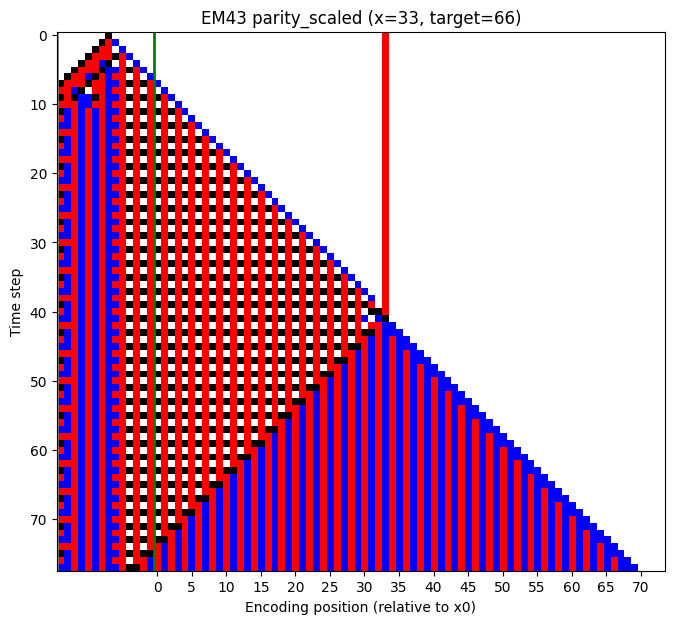

<Figure size 640x480 with 0 Axes>

x=34 | prediction=34 | expected=34 | valid=True | halt_time=79


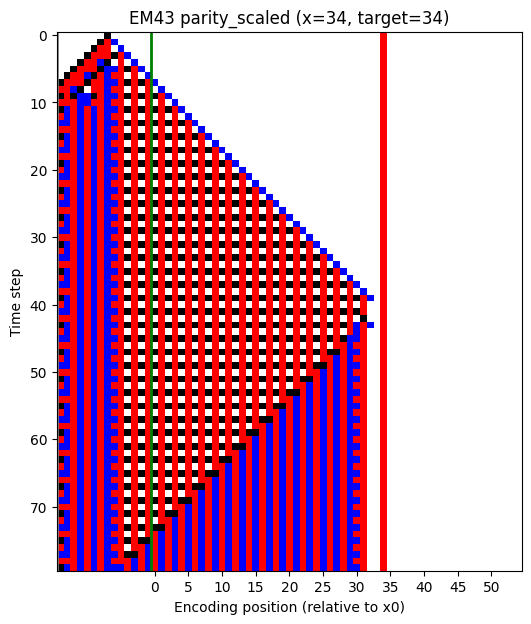

<Figure size 640x480 with 0 Axes>

In [5]:
# Space-time diagrams for the odd and even cases shown in the paper
for x in [33, 34]:
    enc_vis, target_vis = build_single_input_task(
        inputs=[x], target_fn=target_fn
    )
    out = evaluator.run_single(
        rule_full=rule_full, program=program, enc=enc_vis[0],
        return_trajectory=True,
    )
    print(
        f"x={x} | prediction={out['pred']} | expected={int(target_vis[0])} "
        f"| valid={out['valid']} | halt_time={out['halt_time']}"
    )
    evaluator.plot_trajectory(
        out["trajectory"],
        title=f"EM43 parity_scaled (x={x}, target={int(target_vis[0])})",
        figsize=(16, 7), tick_step=5,
    )
    plt.savefig(
        DRIVE_ROOT / f"parity_scaled_space_time_x{x}.png",
        dpi=300, bbox_inches="tight",
    )
    plt.show()


# 4. Evaluate all runs on x=31..1000

In [6]:
# Evaluate both independent runs on the extrapolation interval x = 31..1000
import pandas as pd

test_inputs = range(31, 1001)
encoded_inputs, targets = build_single_input_task(
    inputs=test_inputs, target_fn=target_fn
)
targets = np.asarray(targets, dtype=np.int64)

rows = []
for genome_path in genome_paths:
    data = np.load(genome_path, allow_pickle=True)
    current_rule = np.asarray(data["rule_full"], dtype=np.uint8).reshape(-1)
    current_program = np.asarray(data["program"], dtype=np.uint8).reshape(-1)
    enforce_immutables_full(current_rule)
    current_run = int(data["run"]) if "run" in data else int(genome_path.stem.split("_")[-1])
    current_eval = EM43NumpyEvaluator(
        Lp=len(current_program), Ls=4, T_max=10000,
        right_padding=20, extend_margin=3, extend_by=20,
    )
    preds = np.full(len(encoded_inputs), -1, dtype=np.int64)
    valid = np.zeros(len(encoded_inputs), dtype=bool)
    halt_times = np.full(len(encoded_inputs), -1, dtype=np.int64)
    for i, enc in enumerate(encoded_inputs):
        out = current_eval.run_single(
            rule_full=current_rule, program=current_program, enc=enc,
            return_trajectory=False,
        )
        preds[i] = -1 if out["pred"] is None else int(out["pred"])
        valid[i] = bool(out["valid"])
        halt_times[i] = -1 if out["halt_time"] is None else int(out["halt_time"])
    correct = valid & (preds == targets)
    valid_preds = valid & (preds >= 0)
    test_mae_valid_only = (
        float(np.mean(np.abs(preds[valid_preds] - targets[valid_preds])))
        if np.any(valid_preds) else float("nan")
    )
    rows.append({
        "run": current_run,
        "accuracy": float(correct.mean()),
        "valid_fraction": float(valid.mean()),
        "test_mae_valid_only": test_mae_valid_only,
        "n_correct": int(correct.sum()),
        "n_total": int(len(targets)),
        "n_wrong_or_invalid": int((~correct).sum()),
        "mean_halt_time_valid": float(halt_times[valid].mean()) if np.any(valid) else float("nan"),
        "genome_file": genome_path.name,
    })

rows.sort(key=lambda r: r["run"])
results_df = pd.DataFrame(rows)
display(results_df)
results_path = DRIVE_ROOT / "parity_scaled_extrapolation_results.csv"
results_df.to_csv(results_path, index=False)
print("Saved:", results_path)
print("Mean run accuracy:", results_df["accuracy"].mean())
print("Mean valid fraction:", results_df["valid_fraction"].mean())


,run,accuracy,valid_fraction,test_mae_valid_only,n_correct,n_total,n_wrong_or_invalid,mean_halt_time_valid,genome_file
0,1,1.0,1.0,0.0,970,970,0,1042.000000,best_em43_parity_scaled_run_001.npz
1,2,1.0,1.0,0.0,970,970,0,915.665979,best_em43_parity_scaled_run_002.npz


Saved: /content/drive/MyDrive/EM43/parity_scaled_extrapolation_results.csv
Mean run accuracy: 1.0
Mean valid fraction: 1.0


# 5. Runtime and halting analysis

,task,run,input,expected,predicted,valid,correct,halt_time,extensions,runtime_median_sec
0,parity_scaled,1,10,10,10,True,True,31,0,0.001685
1,parity_scaled,1,20,20,20,True,True,51,0,0.001096
2,parity_scaled,1,50,50,50,True,True,111,0,0.002234
3,parity_scaled,1,100,100,100,True,True,211,0,0.004083
4,parity_scaled,1,200,200,200,True,True,411,0,0.009430
5,parity_scaled,1,500,500,500,True,True,1011,0,0.030307
6,parity_scaled,1,1000,1000,1000,True,True,2011,0,0.065488


Saved: /content/drive/MyDrive/EM43/parity_scaled_runtime_analysis.csv


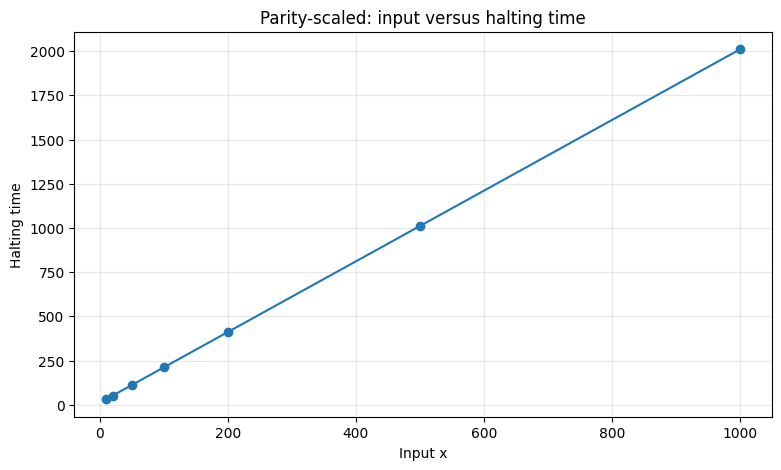

In [7]:
# Runtime and halting-time analysis using Run 1
import time
probe_inputs = [10, 20, 50, 100, 200, 500, 1000]
runtime_rows = []
for x in probe_inputs:
    encs, ys = build_single_input_task(inputs=[x], target_fn=target_fn)
    enc = encs[0]
    # Warm-up
    evaluator.run_single(rule_full=rule_full, program=program, enc=enc, return_trajectory=False)
    timings = []
    last = None
    for _ in range(5):
        t0 = time.perf_counter()
        last = evaluator.run_single(rule_full=rule_full, program=program, enc=enc, return_trajectory=False)
        timings.append(time.perf_counter() - t0)
    runtime_rows.append({
        "task": task_alias, "run": 1, "input": x,
        "expected": int(ys[0]), "predicted": last["pred"],
        "valid": bool(last["valid"]),
        "correct": bool(last["valid"] and last["pred"] == int(ys[0])),
        "halt_time": last["halt_time"],
        "extensions": last["n_extensions"],
        "runtime_median_sec": float(np.median(timings)),
    })
runtime_df = pd.DataFrame(runtime_rows)
display(runtime_df)
runtime_path = DRIVE_ROOT / "parity_scaled_runtime_analysis.csv"
runtime_df.to_csv(runtime_path, index=False)
print("Saved:", runtime_path)

plt.figure(figsize=(9, 5))
plt.plot(runtime_df["input"], runtime_df["halt_time"], marker="o")
plt.xlabel("Input x"); plt.ylabel("Halting time")
plt.title("Parity-scaled: input versus halting time")
plt.grid(alpha=0.3)
plt.savefig(DRIVE_ROOT / "parity_scaled_input_halt_time.png", dpi=300, bbox_inches="tight")
plt.show()
